## 1. Initialize the Kaggle environment

Import the foundational libraries used throughout the analysis and inspect the files mounted in the Kaggle input directory. This cell also imports `kagglehub`, which can be used to attach Kaggle datasets and other resources to the notebook environment.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


## 2. Load the credit card transaction dataset

Read the ULB credit card fraud dataset from Kaggle into a pandas DataFrame. Display the dataset dimensions and a preview of the first few transactions to confirm that the file loaded successfully and to inspect its columns.

In [2]:
file_path = '/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Check the dataset dimensions

Display the number of rows and columns in the loaded dataset. This gives a quick view of the dataset's overall size before beginning the detailed exploration.

In [3]:
df.shape


(284807, 31)

## 4. Inspect data types, summary statistics, and missing values

Review the DataFrame schema, descriptive statistics, and total number of missing values. This helps identify data types, feature ranges, and basic data-quality issues that may affect preprocessing and model development.

In [4]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



Missing values:
0


## 5. Establish the dataset's baseline characteristics

Count exact duplicate rows, examine the distribution of the target variable (`Class`), and calculate the legitimate-to-fraud transaction imbalance ratio. Also inspect transaction amounts and the time span represented by the dataset. These checks establish the key characteristics of this highly imbalanced fraud-detection problem.

In [5]:

# 1. Check duplicate transactions
print("Duplicate rows:", df.duplicated().sum())

# 2. Examine the target variable
class_counts = df["Class"].value_counts().sort_index()

print("\nTransaction counts:")
print(class_counts)

# 3. Calculate class percentages
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print("\nClass percentages:")
print(class_percentages)

# 4. Calculate the imbalance ratio
legitimate = class_counts.get(0, 0)
fraud = class_counts.get(1, 0)

print(f"\nLegitimate transactions: {legitimate:,}")
print(f"Fraudulent transactions: {fraud:,}")
print(f"Imbalance ratio: {legitimate / fraud:.2f}:1")

# 5. Examine transaction amounts
print("\nTransaction amount statistics:")
display(df["Amount"].describe())

# 6. Examine the time range
print("\nTransaction time range:")
print("Start:", df["Time"].min())
print("End:", df["Time"].max())
print("Duration in hours:", (df["Time"].max() - df["Time"].min()) / 3600)


Duplicate rows: 1081

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Legitimate transactions: 284,315
Fraudulent transactions: 492
Imbalance ratio: 577.88:1

Transaction amount statistics:


count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


Transaction time range:
Start: 0.0
End: 172792.0
Duration in hours: 47.99777777777778


*** Investigate duplicates

## 6. Investigate duplicate transaction groups

Identify every row that belongs to an exact duplicate group, then examine the class distribution within those groups. Finally, check whether identical feature values ever appear with conflicting fraud labels. This helps determine whether duplicate removal could discard fraud examples or introduce label ambiguity.

In [6]:

# Identify every row that belongs to a duplicate group
duplicate_mask = df.duplicated(keep=False)
duplicate_df = df.loc[duplicate_mask]

print("Rows belonging to duplicate groups:", len(duplicate_df))

# Distribution of duplicate rows by class
print("\nDuplicate rows by class:")
print(duplicate_df["Class"].value_counts().sort_index())

# Compare with the complete dataset
print("\nClass distribution among duplicate rows (%):")
print(duplicate_df["Class"].value_counts(normalize=True) * 100)

# Check whether identical feature values ever have conflicting labels
feature_cols = [c for c in df.columns if c != "Class"]

label_conflicts = (
    df.groupby(feature_cols, dropna=False)["Class"]
      .nunique()
      .gt(1)
)

print("\nFeature-identical groups with conflicting labels:",
      label_conflicts.sum())


Rows belonging to duplicate groups: 1854

Duplicate rows by class:
Class
0    1822
1      32
Name: count, dtype: int64

Class distribution among duplicate rows (%):
Class
0    98.274002
1     1.725998
Name: proportion, dtype: float64

Feature-identical groups with conflicting labels: 0


## 7. Assess the effect of removing exact duplicates

Create a deduplicated copy of the dataset and compare its dimensions and class distribution with the original data. In particular, quantify how many fraud cases are removed and how the fraud percentage changes. This provides evidence for the duplicate-handling decision used during model preparation.

In [7]:

# Compare original dataset with deduplicated dataset
df_dedup = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("After removing duplicates:", df_dedup.shape)

print("\nOriginal class distribution:")
print(df["Class"].value_counts().sort_index())

print("\nDeduplicated class distribution:")
print(df_dedup["Class"].value_counts().sort_index())

print("\nFraud cases removed:",
      int(df["Class"].sum() - df_dedup["Class"].sum()))

print("\nFraud percentage after deduplication:",
      df_dedup["Class"].mean() * 100)


Original dataset: (284807, 31)
After removing duplicates: (283726, 31)

Original class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Deduplicated class distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud cases removed: 19

Fraud percentage after deduplication: 0.1667101358352777


## 8. Explore transaction amount distributions

Visualize the original transaction amount distribution, its `log1p` transformation, and the amount distributions for legitimate and fraudulent transactions. The logarithmic view helps reveal structure in a strongly right-skewed variable, while the class comparison provides an initial look at whether transaction amount differs between the two classes.

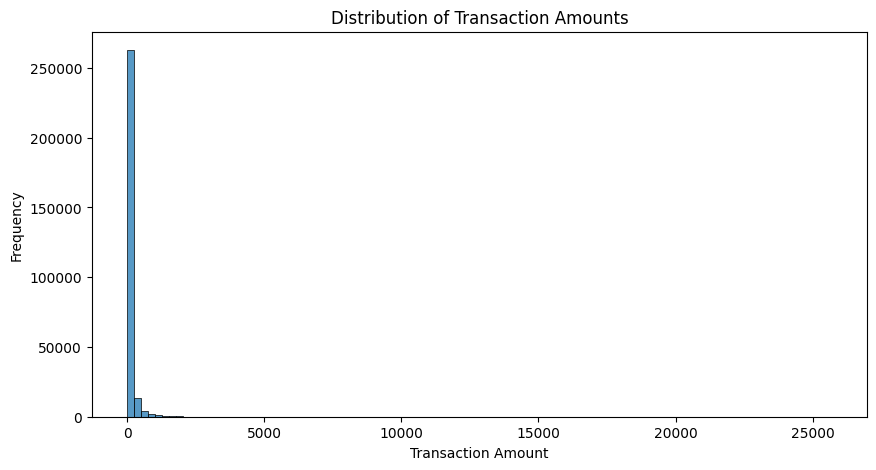

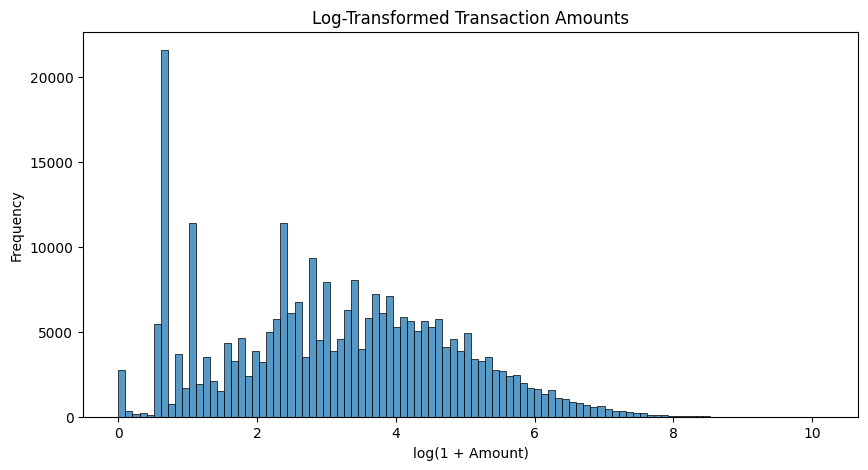

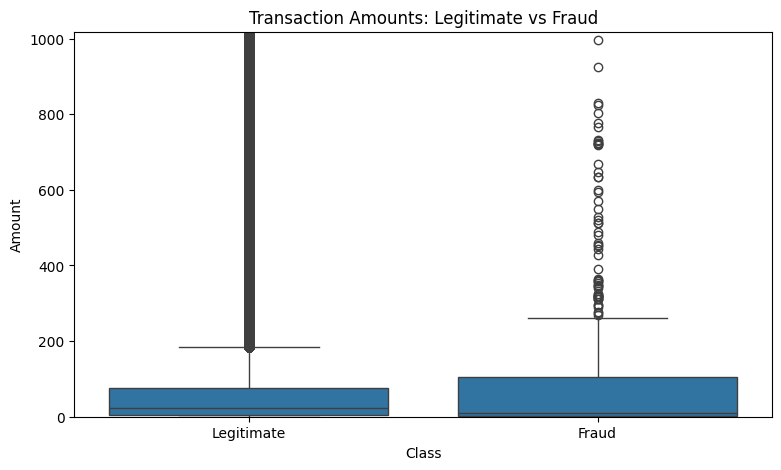

In [8]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Original transaction amount distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["Amount"], bins=100)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

# 2. Log-transformed amount distribution
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df["Amount"]), bins=100)
plt.title("Log-Transformed Transaction Amounts")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Frequency")
plt.show()

# 3. Compare legitimate and fraudulent amounts
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.ylim(0, df["Amount"].quantile(0.99))
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amounts: Legitimate vs Fraud")
plt.show()


## 9. Compare transaction amounts on a logarithmic scale

Revisit the legitimate-versus-fraud amount boxplot using a logarithmic y-axis. This makes differences across a wide range of transaction values easier to inspect without allowing a small number of large transactions to dominate the visual scale.

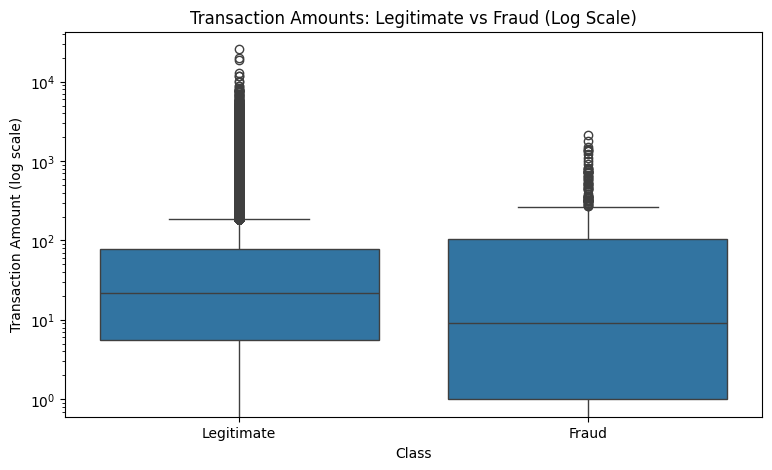

In [9]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.yscale("log")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amounts: Legitimate vs Fraud (Log Scale)")
plt.ylabel("Transaction Amount (log scale)")

plt.show()

## 10. Build and evaluate the Logistic Regression baseline

Remove exact duplicate records, separate predictors from the fraud label, and create a stratified train/test split so the rare fraud class is represented in both sets. Build a pipeline that standardizes the features before fitting a class-weighted Logistic Regression model. Evaluate its test-set predictions using a confusion matrix, classification metrics, PR-AUC, and ROC-AUC. The test set is reserved for evaluation rather than model tuning.

In [10]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# 1. Remove exact duplicate records
df_model = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("After deduplication:", df_model.shape)

# 2. Separate features (X) and target (y)
X = df_model.drop(columns=["Class"])
y = df_model["Class"]

# 3. Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nFraud distribution in training data:")
print(y_train.value_counts())

print("\nFraud distribution in testing data:")
print(y_test.value_counts())

# 4. Build Logistic Regression pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# 5. Train the model
model.fit(X_train, y_train)

print("\nModel training completed!")

# 6. Predict fraud probabilities and classes
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 7. Evaluate the model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("PR-AUC (Average Precision):",
      average_precision_score(y_test, y_prob))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))


Original dataset: (284807, 31)
After deduplication: (283726, 31)

Training samples: 226980
Testing samples: 56746

Fraud distribution in training data:
Class
0    226602
1       378
Name: count, dtype: int64

Fraud distribution in testing data:
Class
0    56651
1       95
Name: count, dtype: int64

Model training completed!

Confusion Matrix:
[[55262  1389]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

PR-AUC (Average Precision): 0.6719244530518995
ROC-AUC: 0.9656548079701293


## 11. Create a validation set for threshold selection

Split the training portion again into a model-fitting subset and a validation subset, preserving the class ratio. Train a fresh class-weighted Logistic Regression pipeline on the fitting subset and generate fraud probabilities for the validation set. These probabilities will be used to study decision thresholds without using the final test set.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score

# Split training data into model-training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a fresh Logistic Regression pipeline
validation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

validation_model.fit(X_fit, y_fit)

# Get fraud probabilities on validation data
val_prob = validation_model.predict_proba(X_val)[:, 1]

print("Model trained on validation-training subset.")
print("Validation samples:", len(X_val))
print("Fraud cases in validation:", int(y_val.sum()))

Model trained on validation-training subset.
Validation samples: 45396
Fraud cases in validation: 76


## 12. Measure Logistic Regression performance at different thresholds

Convert the validation probabilities into fraud/legitimate predictions across a range of decision thresholds. For each threshold, calculate precision, recall, the number of transactions flagged, and the number of fraud cases missed. This shows how changing the threshold affects the trade-off between catching fraud and generating alerts.

In [12]:
thresholds = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

results = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    predictions = (val_prob >= threshold).astype(int)

    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "Flagged Transactions": int(predictions.sum()),
        "Missed Fraud": int(((y_val == 1) & (predictions == 0)).sum())
    })

threshold_df = pd.DataFrame(results)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,Threshold,Precision,Recall,Flagged Transactions,Missed Fraud
0,0.05,0.56%,96.05%,13049,3
1,0.10,0.96%,94.74%,7516,4
2,0.15,1.38%,94.74%,5217,4
3,0.20,1.78%,92.11%,3936,6
4,0.30,2.69%,90.79%,2562,7
5,0.40,3.94%,90.79%,1752,7
6,0.50,5.42%,89.47%,1254,8
7,0.60,7.73%,89.47%,880,8
8,0.70,10.41%,89.47%,653,8
9,0.80,14.16%,86.84%,466,10


## 13. Visualize the precision–recall threshold trade-off

Plot validation precision and recall against the decision threshold. Use the chart to see how a stricter threshold changes the balance between alert quality and fraud coverage, supporting the selection of an operating point based on business priorities.

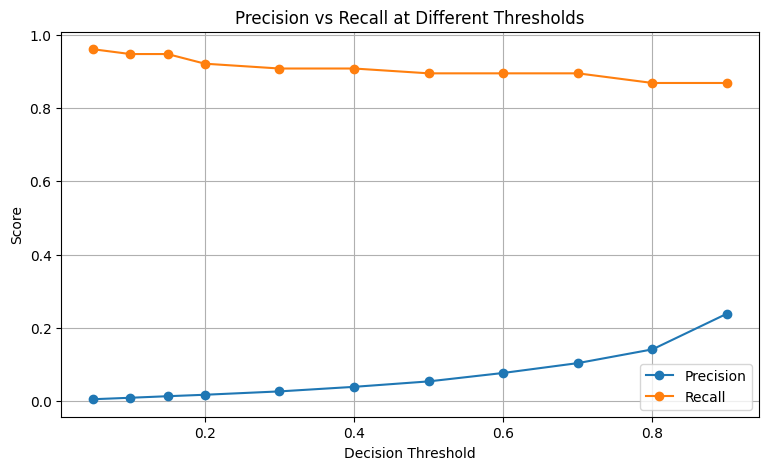

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall at Different Thresholds")
plt.legend()
plt.grid(True)
plt.show()

## 14. Refit Logistic Regression and evaluate the selected threshold

Retrain the Logistic Regression pipeline on the complete training set, then score the untouched test set. Apply the selected 0.90 threshold to convert probabilities into fraud alerts and report the confusion matrix, classification report, PR-AUC, and ROC-AUC. This provides the final test-set assessment of the Logistic Regression baseline at the chosen operating threshold.

In [14]:
# Refit the model on the complete training dataset
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Predict fraud probabilities on the untouched test set
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply our selected threshold
chosen_threshold = 0.90
test_pred = (test_prob >= chosen_threshold).astype(int)

# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Legitimate", "Fraud"]
))

print("PR-AUC:", average_precision_score(y_test, test_prob))
print("ROC-AUC:", roc_auc_score(y_test, test_prob))

Confusion Matrix:
[[56429   222]
 [   16    79]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.26      0.83      0.40        95

    accuracy                           1.00     56746
   macro avg       0.63      0.91      0.70     56746
weighted avg       1.00      1.00      1.00     56746

PR-AUC: 0.6719244530518995
ROC-AUC: 0.9656548079701293


SMOTE - Synthetic Minority Over sampling technique

## 15. Install the imbalanced-learn package

Install `imbalanced-learn`, which provides the SMOTE oversampling algorithm and a pipeline implementation that can apply resampling during model training.

In [15]:
!pip install -q imbalanced-learn

## 16. Import SMOTE and its supporting components

Import SMOTE, the imbalanced-learn pipeline, feature scaling, Logistic Regression, and the evaluation metrics needed for the oversampling experiment. This prepares a separate model pipeline so the effect of SMOTE can be examined against the class-weighted baseline.

In [16]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    average_precision_score,
    roc_auc_score
)

## 17. Train Logistic Regression with SMOTE oversampling

Build a pipeline that standardizes the training features, applies SMOTE to the fitting subset, and trains Logistic Regression on the resampled data. Keeping SMOTE inside the pipeline ensures that synthetic examples are generated from the training subset rather than from validation or test data.

In [17]:
smote_model = ImbPipeline([
    ("scaler", StandardScaler()),

    ("smote", SMOTE(
        sampling_strategy="auto",
        random_state=42
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
smote_model.fit(X_fit, y_fit)

print("SMOTE model training completed!")

SMOTE model training completed!


## 18. Inspect class counts before and after SMOTE

Display the class distribution in the original fitting subset, then apply the fitted scaling and SMOTE steps to inspect the resampled class counts. This makes the effect of oversampling visible and confirms how the minority fraud class is expanded for model training.

In [18]:
from collections import Counter

print("Before SMOTE:")
print(Counter(y_fit))

X_fit_scaled = smote_model.named_steps["scaler"].transform(X_fit)

X_resampled, y_resampled = smote_model.named_steps["smote"].fit_resample(
    X_fit_scaled, y_fit
)

print("\nAfter SMOTE:")
print(Counter(y_resampled))

Before SMOTE:
Counter({0: 181282, 1: 302})

After SMOTE:
Counter({0: 181282, 1: 181282})


## 19. Generate SMOTE model probabilities on validation data

Use the trained SMOTE pipeline to estimate the probability that each validation transaction is fraudulent. These probability scores are the basis for threshold-based predictions and ranking metrics in the next evaluation step.

In [19]:
smote_val_prob = smote_model.predict_proba(X_val)[:, 1]
smote_val_prob

array([0.00337192, 0.02333503, 0.01113681, ..., 0.02519811, 0.00597622,
       0.00149797])

## 20. Evaluate the SMOTE model at the selected threshold

Apply a 0.90 decision threshold to the validation fraud probabilities and calculate precision, recall, PR-AUC, and ROC-AUC. This evaluates the SMOTE model's alert performance and probability ranking on data that was not used to generate synthetic training examples.

In [20]:
threshold = 0.90

smote_val_pred = (smote_val_prob >= threshold).astype(int)

print("SMOTE Validation Results")
print("------------------------")

print("Precision:",
      precision_score(y_val, smote_val_pred, zero_division=0))

print("Recall:",
      recall_score(y_val, smote_val_pred, zero_division=0))

print("PR-AUC:",
      average_precision_score(y_val, smote_val_prob))

print("ROC-AUC:",
      roc_auc_score(y_val, smote_val_prob))

SMOTE Validation Results
------------------------
Precision: 0.1935483870967742
Recall: 0.868421052631579
PR-AUC: 0.813821419485991
ROC-AUC: 0.9732391299298555


## 21. Compare class weighting with SMOTE

Compare the class-weighted Logistic Regression baseline and the SMOTE-based Logistic Regression model on the same validation set and at the same 0.90 threshold. Report precision, recall, PR-AUC, ROC-AUC, alert volume, and missed fraud cases to assess whether oversampling improves the practical trade-off.

In [21]:
comparison = []

for name, probabilities in [
    ("Class-weighted Logistic Regression", val_prob),
    ("SMOTE Logistic Regression", smote_val_prob)
]:
    predictions = (probabilities >= 0.90).astype(int)

    comparison.append({
        "Model": name,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Flagged Transactions": int(predictions.sum()),
        "Missed Fraud": int(((y_val == 1) & (predictions == 0)).sum())
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

,Model,Precision,Recall,PR-AUC,ROC-AUC,Flagged Transactions,Missed Fraud
0,Class-weighted Logistic Regression,0.2391,0.8684,0.8139,0.9749,276,10
1,SMOTE Logistic Regression,0.1935,0.8684,0.8138,0.9732,341,10


## 22. Train a Random Forest model

Configure a Random Forest classifier with class weighting to account for the rare fraud class. Fit the ensemble on the training-fitting subset. Random Forest provides a nonlinear tree-based comparison to the Logistic Regression baseline.

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_fit, y_fit)

print("Random Forest training completed!")

Random Forest training completed!


## 23. Generate Random Forest fraud probabilities

Use the trained Random Forest to estimate fraud probabilities for the validation transactions. The resulting scores can be converted into alerts at a chosen threshold and evaluated with threshold-independent ranking metrics.

In [23]:
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]
rf_val_prob

array([0., 0., 0., ..., 0., 0., 0.])

## 24. Evaluate Random Forest validation predictions

Apply a 0.50 decision threshold to the Random Forest validation probabilities and calculate precision, recall, PR-AUC, and ROC-AUC. This cell reports the model's validation performance at the selected threshold.

In [24]:
threshold = 0.50

rf_val_pred = (rf_val_prob >= threshold).astype(int)

print("Random Forest Validation Results")
print("------------------------")

print("Precision:",
      precision_score(y_val, rf_val_pred, zero_division=0))

print("Recall:",
      recall_score(y_val, rf_val_pred, zero_division=0))

print("PR-AUC:",
      average_precision_score(y_val, rf_val_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, rf_val_pred))

Random Forest Validation Results
------------------------
Precision: 0.9682539682539683
Recall: 0.8026315789473685
PR-AUC: 0.7774816369498952
ROC-AUC: 0.9012937241603568


## XGBoost Gradient

## 25. Install XGBoost

Install the XGBoost package, which provides the gradient-boosted tree classifier used in the next experiment.

In [25]:
!pip install -q xgboost

## 26. Configure and train the XGBoost model

Calculate the ratio of legitimate to fraudulent transactions in the fitting data and pass it to XGBoost through `scale_pos_weight` to account for class imbalance. Configure the boosted-tree model, train it on the fitting subset, and record training time. XGBoost provides a gradient-boosting comparison to the Random Forest and Logistic Regression models.

In [26]:
from xgboost import XGBClassifier
import time

# Calculate class imbalance ratio from training data
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_weight = negative_count / positive_count

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_model.fit(X_fit, y_fit)

print("XGBoost training completed!")
print(f"Training time: {time.time() - start_time:.2f} seconds")

XGBoost training completed!
Training time: 2.92 seconds


## 27. Evaluate the initial XGBoost model

Generate fraud probabilities for the validation set, convert them into predictions using the default 0.50 threshold, and report the confusion matrix and classification report. Also calculate PR-AUC and ROC-AUC from the probability scores to assess how well the model ranks fraudulent transactions.

In [27]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

# Initial evaluation at default threshold
threshold = 0.50

xgb_val_pred = (xgb_val_prob >= threshold).astype(int)

print("XGBoost Validation Results")
print("--------------------------")

print("Confusion Matrix:")
print(confusion_matrix(y_val, xgb_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, xgb_val_pred))

print("PR-AUC:", average_precision_score(y_val, xgb_val_prob))
print("ROC-AUC:", roc_auc_score(y_val, xgb_val_prob))

XGBoost Validation Results
--------------------------
Confusion Matrix:
[[45301    19]
 [   10    66]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.78      0.87      0.82        76

    accuracy                           1.00     45396
   macro avg       0.89      0.93      0.91     45396
weighted avg       1.00      1.00      1.00     45396

PR-AUC: 0.8756226288254088
ROC-AUC: 0.9753154468806615


## 28. Verify the XGBoost training and validation split

Print the dimensions of the fitting and validation datasets and the number of fraud and legitimate cases in validation. This is a quick consistency check that makes the sample sizes and class distribution explicit before threshold analysis.

In [28]:
print("Training data:", X_fit.shape)
print("Validation data:", X_val.shape)
print("Validation fraud cases:", y_val.sum())
print("Validation legitimate cases:", (y_val == 0).sum())

Training data: (181584, 30)
Validation data: (45396, 30)
Validation fraud cases: 76
Validation legitimate cases: 45320


## 29. Compare XGBoost performance across decision thresholds

Evaluate XGBoost validation probabilities over several decision thresholds. For each threshold, calculate precision, recall, F1, fraud caught, fraud missed, false alerts, and total alerts. This provides a practical view of the trade-offs involved in choosing an operating threshold for fraud review.

In [29]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50,
              0.60, 0.70, 0.80, 0.90]

results = []

for threshold in thresholds:
    y_pred = (xgb_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "Fraud Caught": tp,
        "Fraud Missed": fn,
        "False Alerts": fp,
        "Total Alerts": tp + fp
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,Fraud Caught,Fraud Missed,False Alerts,Total Alerts
0,0.1,0.2746,0.8816,0.4188,67,9,177,244
1,0.2,0.4685,0.8816,0.6119,67,9,76,143
2,0.3,0.6036,0.8816,0.7166,67,9,44,111
3,0.4,0.7053,0.8816,0.7836,67,9,28,95
4,0.5,0.7765,0.8684,0.8199,66,10,19,85
5,0.6,0.7765,0.8684,0.8199,66,10,19,85
6,0.7,0.8354,0.8684,0.8516,66,10,13,79
7,0.8,0.8904,0.8553,0.8725,65,11,8,73
8,0.9,0.9014,0.8421,0.8707,64,12,7,71


## 30. Train the final XGBoost model and evaluate on the test set

Recalculate the class-imbalance weight using the complete training set, configure the final XGBoost classifier, and fit it on all training data. Generate probabilities for the untouched test set, apply the selected 0.70 threshold, and report the confusion matrix, classification report, PR-AUC, and ROC-AUC. This is the final test-set evaluation of the selected XGBoost approach.

In [30]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Calculate class imbalance from complete training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_weight = negative_count / positive_count

# Build final XGBoost model
final_xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train on complete training data
final_xgb_model.fit(X_train, y_train)

# Evaluate on untouched test data
test_prob = final_xgb_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
selected_threshold = 0.70
test_pred = (test_prob >= selected_threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

print("PR-AUC:", average_precision_score(y_test, test_prob))
print("ROC-AUC:", roc_auc_score(y_test, test_prob))

Confusion Matrix:
[[56629    22]
 [   20    75]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.77      0.79      0.78        95

    accuracy                           1.00     56746
   macro avg       0.89      0.89      0.89     56746
weighted avg       1.00      1.00      1.00     56746

PR-AUC: 0.8137015733273856
ROC-AUC: 0.9750260366101215


## Which transaction features contribute most to identifying fraudulent transactions?

### We'll start with XGBoost's built-in feature importance. Then we'll use SHAP to understand how individual features influence predictions.

## 31. Examine XGBoost feature importance

Extract the feature-importance scores from the final XGBoost model, rank the predictors, and display the top 15 features in both tabular and chart form. This gives a model-level view of which input features the fitted ensemble relies on most; importance scores should not be interpreted as proof of causation.

,Feature,Importance
14,V14,0.403892
10,V10,0.073243
4,V4,0.047190
8,V8,0.042058
12,V12,0.035383
13,V13,0.029620
19,V19,0.028720
20,V20,0.027416
3,V3,0.021353
29,Amount,0.019984


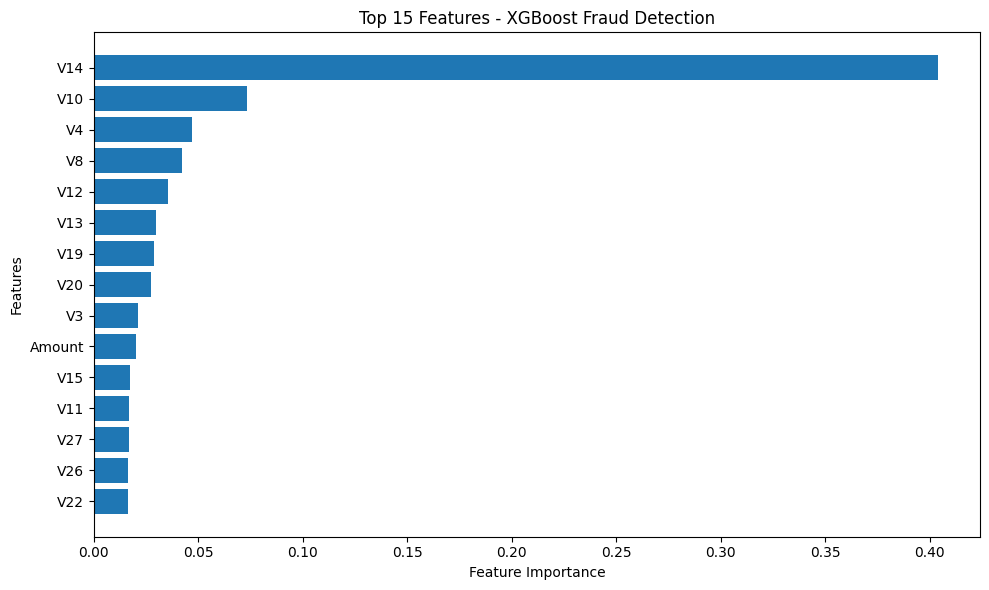

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_xgb_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

# Display top 15 features
display(importance_df.head(15))

# Plot
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df.head(15)["Feature"][::-1],
    importance_df.head(15)["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - XGBoost Fraud Detection")
plt.tight_layout()
plt.show()

## 32. Install SHAP for model explainability

Install SHAP, a library for explaining the contribution of input features to individual predictions and summarizing feature effects across a sample of transactions.

In [32]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


How to read your SHAP summary plot
- X-axis: SHAP value, showing the direction and magnitude of impact on the model output.
  - Negative: pushes the prediction toward legitimate.
  - Positive: pushes the prediction toward fraud.
- Color: Actual feature value.
  - Red/pink: High value.
  - Blue: Low value.
- Each dot: One transaction from our 1,000-transaction sample.

## 33. Explain XGBoost predictions with SHAP

Select a representative sample of test transactions and use `TreeExplainer` to calculate SHAP values for the final XGBoost model. Handle alternative SHAP output formats, then create a summary plot showing the direction and magnitude of feature contributions across the sample. The plot supports global interpretation of the model while the input features remain anonymized PCA components.

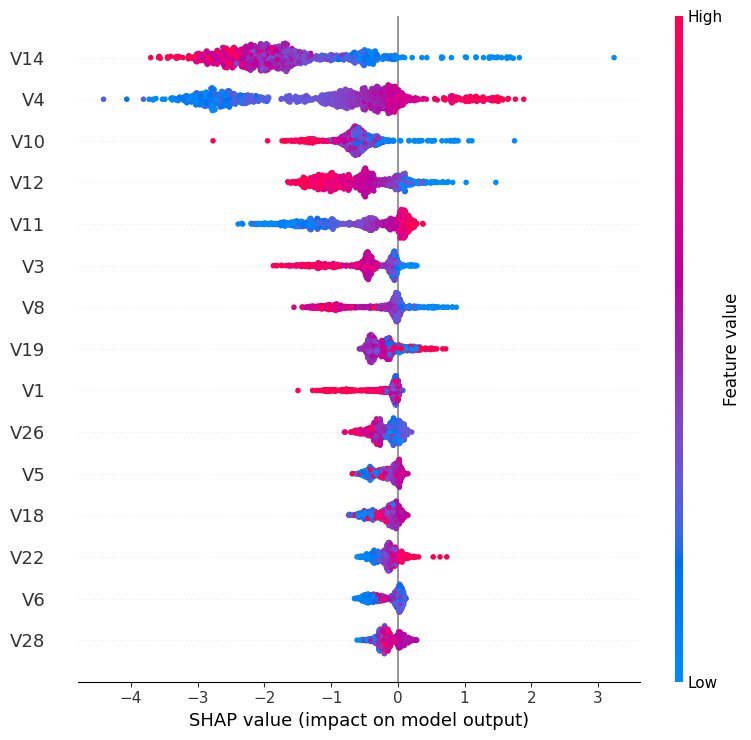

In [33]:
import shap
import numpy as np

# Use a representative sample of unseen test transactions
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

# Explain the trained XGBoost model
explainer = shap.TreeExplainer(final_xgb_model)
shap_values = explainer.shap_values(X_shap)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

# Global explanation
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15
)